<a href="https://colab.research.google.com/github/vjshivani25-hub/DLAC/blob/main/skill6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Install and Import Libraries

In this step, we install and import the Python libraries required
for dataset auditing, image processing, data analysis and visualization.

- OpenCV: used for image reading, image quality analysis and drawing bounding boxes.
- NumPy: used for numerical calculations.
- Pandas: used for storing and analyzing audit results in tables.
- Matplotlib: used for plotting graphs.
- Seaborn: used for statistical visualizations.
- PyYAML: used for reading the dataset configuration file.

These libraries help us analyze the dataset and identify problems
in images and annotations.

In [1]:
!pip -q install opencv-python-headless pyyaml seaborn

In [2]:
import os
import zipfile
import urllib.request
from pathlib import Path
from collections import Counter

import cv2
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Download and Extract the Dataset

In this step, we download the COCO128 object detection dataset.

COCO128 is a small dataset containing images with object annotations
in YOLO format.

The dataset contains:
- Images: real-world images containing multiple objects.
- Labels: text files containing class IDs and bounding-box coordinates.
- Dataset configuration: information about class names and dataset paths.

We download the dataset ZIP file and extract it into Google Colab.
This dataset will be used for class distribution analysis,
image quality inspection and annotation validation.

In [10]:
from google.colab import files
import zipfile
import os

# Upload the downloaded ZIP
uploaded = files.upload()

zip_path = "/content/coco128.zip"

# Extract dataset
extract_path = "/content/datasets"
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Saving coco128.zip to coco128 (1).zip
Dataset extracted successfully!


## 3. Dataset Overview and Class Names

In this step, we examine the structure of the downloaded dataset.

We check:
- Total number of images available.
- Total number of annotation files.
- Number of object classes defined in the dataset.
- Class names and their corresponding class IDs.

This step helps us understand the dataset before performing
class distribution analysis, image quality assessment,
and annotation validation.

In [11]:
from pathlib import Path
import yaml

# Define dataset paths
dataset_path = Path("/content/datasets/coco128")

IMAGE_DIR = dataset_path / "images" / "train2017"
LABEL_DIR = dataset_path / "labels" / "train2017"
YAML_PATH = dataset_path / "coco128.yaml"

# Check dataset folders
print("Dataset exists:", dataset_path.exists())
print("Images folder exists:", IMAGE_DIR.exists())
print("Labels folder exists:", LABEL_DIR.exists())
print("YAML file exists:", YAML_PATH.exists())

Dataset exists: True
Images folder exists: True
Labels folder exists: True
YAML file exists: False


## 4. Dataset Statistics and Class Names

In this step, we examine the basic structure of the dataset.

We calculate the total number of images, annotation files,
and object classes. We also identify vehicle-related
classes such as car, bus, truck and motorcycle.

Since the original configuration file is missing, we use
the standard COCO class names manually.

This helps us understand the dataset before performing
class distribution analysis and image quality assessment.

In [14]:
import os

print("Folders inside /content/datasets:")
print(os.listdir("/content/datasets"))

Folders inside /content/datasets:
['coco128']


In [16]:
import os

root = "/content/datasets/coco128"

for current_path, folders, files in os.walk(root):
    print("\nFolder:", current_path)
    print("Files:", files[:10])


Folder: /content/datasets/coco128
Files: ['README.txt', 'LICENSE']

Folder: /content/datasets/coco128/labels
Files: []

Folder: /content/datasets/coco128/labels/train2017
Files: ['000000000575.txt', '000000000092.txt', '000000000643.txt', '000000000074.txt', '000000000009.txt', '000000000560.txt', '000000000634.txt', '000000000094.txt', '000000000201.txt', '000000000143.txt']

Folder: /content/datasets/coco128/images
Files: []

Folder: /content/datasets/coco128/images/train2017
Files: ['000000000049.jpg', '000000000072.jpg', '000000000595.jpg', '000000000540.jpg', '000000000338.jpg', '000000000510.jpg', '000000000389.jpg', '000000000322.jpg', '000000000431.jpg', '000000000328.jpg']


In [17]:
import os
from pathlib import Path

# Dataset paths
dataset_path = Path("/content/datasets/coco128")
IMAGE_DIR = dataset_path / "images" / "train2017"
LABEL_DIR = dataset_path / "labels" / "train2017"

# Standard COCO 80 class names
class_names = [
    "person", "bicycle", "car", "motorcycle", "airplane",
    "bus", "train", "truck", "boat", "traffic light",
    "fire hydrant", "stop sign", "parking meter", "bench",
    "bird", "cat", "dog", "horse", "sheep", "cow",
    "elephant", "bear", "zebra", "giraffe", "backpack",
    "umbrella", "handbag", "tie", "suitcase", "frisbee",
    "skis", "snowboard", "sports ball", "kite", "baseball bat",
    "baseball glove", "skateboard", "surfboard", "tennis racket",
    "bottle", "wine glass", "cup", "fork", "knife", "spoon",
    "bowl", "banana", "apple", "sandwich", "orange", "broccoli",
    "carrot", "hot dog", "pizza", "donut", "cake", "chair",
    "couch", "potted plant", "bed", "dining table", "toilet",
    "TV", "laptop", "mouse", "remote", "keyboard", "cell phone",
    "microwave", "oven", "toaster", "sink", "refrigerator",
    "book", "clock", "vase", "scissors", "teddy bear",
    "hair drier", "toothbrush"
]

# Collect image files
image_files = [
    f for f in IMAGE_DIR.iterdir()
    if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

# Collect annotation files
label_files = list(LABEL_DIR.glob("*.txt"))

# Vehicle classes
vehicle_names = [
    "bicycle", "car", "motorcycle",
    "bus", "train", "truck"
]

vehicle_ids = {
    i: name
    for i, name in enumerate(class_names)
    if name in vehicle_names
}

# Display statistics
print("=" * 50)
print("          DATASET STATISTICS")
print("=" * 50)

print("Total Images:", len(image_files))
print("Total Annotation Files:", len(label_files))
print("Total Classes:", len(class_names))

print("\nVehicle Classes and IDs:")
print(vehicle_ids)

print("\nAll 80 COCO Classes:")
for i, name in enumerate(class_names):
    print(f"{i}: {name}")

print("=" * 50)

          DATASET STATISTICS
Total Images: 128
Total Annotation Files: 128
Total Classes: 80

Vehicle Classes and IDs:
{1: 'bicycle', 2: 'car', 3: 'motorcycle', 5: 'bus', 6: 'train', 7: 'truck'}

All 80 COCO Classes:
0: person
1: bicycle
2: car
3: motorcycle
4: airplane
5: bus
6: train
7: truck
8: boat
9: traffic light
10: fire hydrant
11: stop sign
12: parking meter
13: bench
14: bird
15: cat
16: dog
17: horse
18: sheep
19: cow
20: elephant
21: bear
22: zebra
23: giraffe
24: backpack
25: umbrella
26: handbag
27: tie
28: suitcase
29: frisbee
30: skis
31: snowboard
32: sports ball
33: kite
34: baseball bat
35: baseball glove
36: skateboard
37: surfboard
38: tennis racket
39: bottle
40: wine glass
41: cup
42: fork
43: knife
44: spoon
45: bowl
46: banana
47: apple
48: sandwich
49: orange
50: broccoli
51: carrot
52: hot dog
53: pizza
54: donut
55: cake
56: chair
57: couch
58: potted plant
59: bed
60: dining table
61: toilet
62: TV
63: laptop
64: mouse
65: remote
66: keyboard
67: cell phone

### 5.1 Class Distribution Calculation

In this step, we read the annotation files of the dataset.

Each annotation line represents one object and contains:
- Class ID
- X-coordinate of bounding box center
- Y-coordinate of bounding box center
- Bounding box width
- Bounding box height

We count the number of objects belonging to each class
using their class IDs.

This analysis helps identify the most frequent and
least frequent object classes in the dataset.

In [18]:
from collections import Counter

# Initialize class counter
class_counts = Counter()

# Count objects from annotation files
for label_file in label_files:

    with open(label_file, "r") as f:
        lines = f.readlines()

    for line in lines:
        values = line.strip().split()

        if len(values) >= 5:
            class_id = int(float(values[0]))
            class_counts[class_id] += 1

# Include all classes, even those with zero objects
distribution = {
    class_names[class_id]: class_counts.get(class_id, 0)
    for class_id in range(len(class_names))
}

# Display class distribution
print("CLASS DISTRIBUTION")
print("-" * 40)

for class_name, count in distribution.items():
    print(f"{class_name:<20}: {count}")

print("-" * 40)

print("Total objects:", sum(class_counts.values()))
print("Classes present:", len(class_counts))
print("Classes absent:", len(class_names) - len(class_counts))

CLASS DISTRIBUTION
----------------------------------------
person              : 261
bicycle             : 6
car                 : 48
motorcycle          : 6
airplane            : 6
bus                 : 7
train               : 4
truck               : 12
boat                : 6
traffic light       : 14
fire hydrant        : 0
stop sign           : 2
parking meter       : 0
bench               : 9
bird                : 16
cat                 : 4
dog                 : 9
horse               : 2
sheep               : 0
cow                 : 0
elephant            : 17
bear                : 1
zebra               : 4
giraffe             : 9
backpack            : 6
umbrella            : 18
handbag             : 20
tie                 : 7
suitcase            : 4
frisbee             : 5
skis                : 1
snowboard           : 7
sports ball         : 6
kite                : 10
baseball bat        : 4
baseball glove      : 7
skateboard          : 5
surfboard           : 0
tennis racket     

### 5.2 Class Distribution Visualization

In this step, we visualize the number of objects belonging
to each class using a bar chart.

The X-axis represents object classes, and the Y-axis
represents the number of annotated objects.

The graph helps identify:
- Frequently occurring classes.
- Rare classes.
- Imbalanced class distribution.
- Classes with zero annotated objects.

Visualization makes the dataset distribution easier
to understand and interpret.

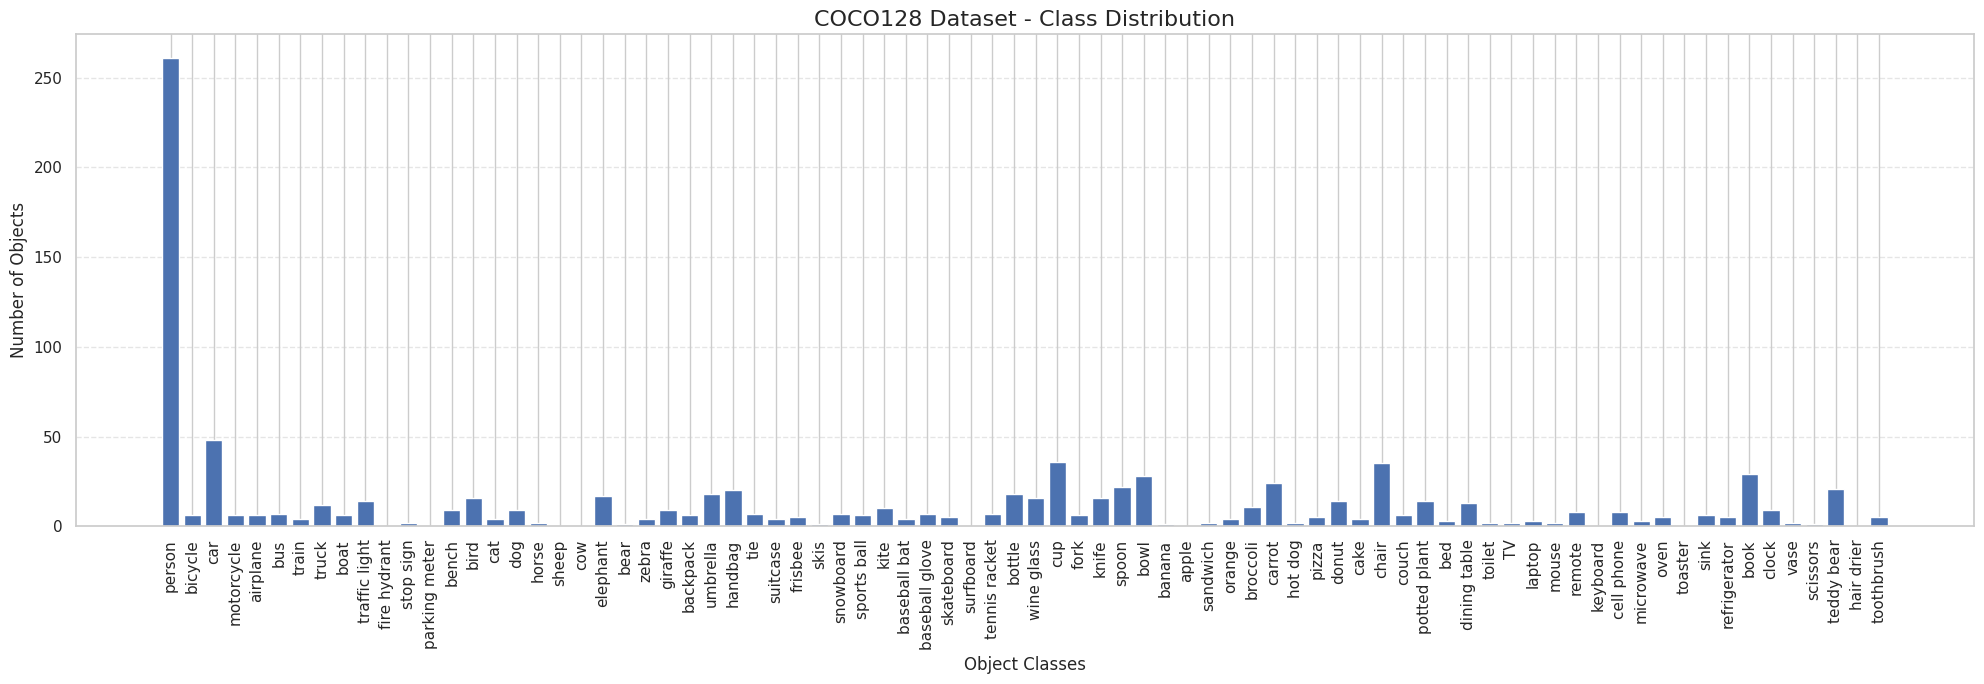

In [19]:
import matplotlib.pyplot as plt

# Prepare data
classes = list(distribution.keys())
counts = list(distribution.values())

# Create bar chart
plt.figure(figsize=(20, 7))

plt.bar(classes, counts)

plt.title("COCO128 Dataset - Class Distribution", fontsize=16)
plt.xlabel("Object Classes", fontsize=12)
plt.ylabel("Number of Objects", fontsize=12)

plt.xticks(rotation=90)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 6. Vehicle Class Distribution Analysis

In this step, we analyze the distribution of vehicle-related
classes in the dataset.

We focus on bicycle, car, motorcycle, bus, train and truck.

The analysis helps us understand the number of examples
available for each vehicle category.

We visualize the vehicle distribution separately to make
the comparison easier and identify underrepresented classes.

In [20]:
# Vehicle class distribution
vehicle_distribution = {
    name: distribution[name]
    for name in vehicle_names
}

print("VEHICLE CLASS DISTRIBUTION")
print("-" * 35)

for name, count in vehicle_distribution.items():
    print(f"{name:<15}: {count}")

print("-" * 35)
print("Total vehicle objects:", sum(vehicle_distribution.values()))

VEHICLE CLASS DISTRIBUTION
-----------------------------------
bicycle        : 6
car            : 48
motorcycle     : 6
bus            : 7
train          : 4
truck          : 12
-----------------------------------
Total vehicle objects: 83


### 6.2 Vehicle Distribution Visualization

In this step, we visualize the distribution of vehicle
classes using a bar chart.

The graph compares the number of annotations for each
vehicle category.

It helps identify dominant and underrepresented vehicle
classes in the dataset.

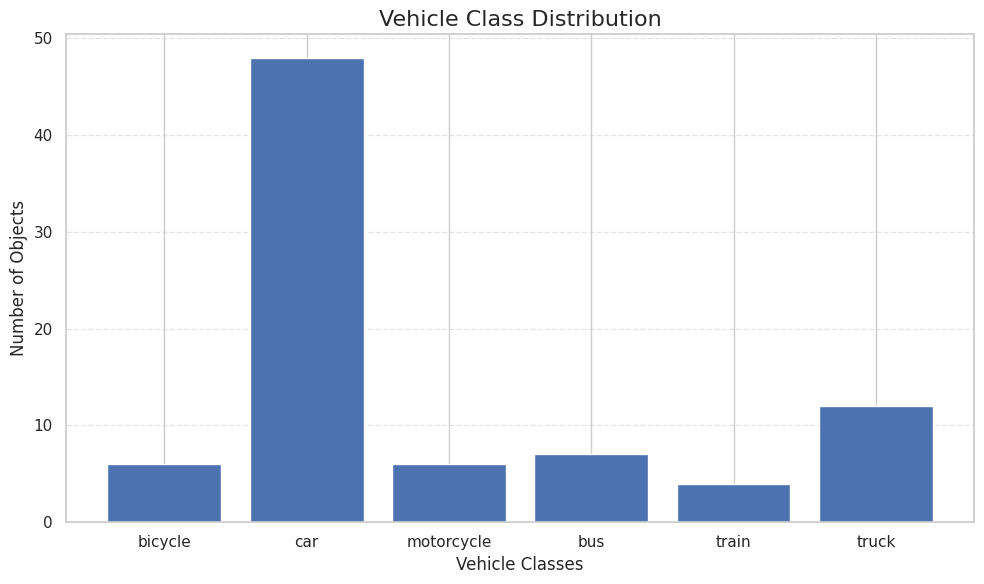

In [21]:
import matplotlib.pyplot as plt

vehicle_classes = list(vehicle_distribution.keys())
vehicle_counts = list(vehicle_distribution.values())

plt.figure(figsize=(10, 6))

plt.bar(vehicle_classes, vehicle_counts)

plt.title("Vehicle Class Distribution", fontsize=16)
plt.xlabel("Vehicle Classes", fontsize=12)
plt.ylabel("Number of Objects", fontsize=12)

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 7.1 Image Dimension Analysis

In this step, we examine the dimensions of all images
in the dataset.

We calculate:
- Image width.
- Image height.
- Minimum and maximum dimensions.
- Average image width and height.

Image dimensions help us understand the resolution and
consistency of the dataset.

Different image sizes may require resizing or preprocessing
before model training.

In [22]:
from PIL import Image
import numpy as np

widths = []
heights = []
valid_images = 0
corrupted_images = []

for image_path in image_files:
    try:
        with Image.open(image_path) as img:
            width, height = img.size

            widths.append(width)
            heights.append(height)

            valid_images += 1

    except Exception as e:
        corrupted_images.append(image_path.name)

print("=" * 40)
print("IMAGE DIMENSION ANALYSIS")
print("=" * 40)

print("Total images checked:", len(image_files))
print("Valid images:", valid_images)
print("Corrupted images:", len(corrupted_images))

print("\nWidth Statistics:")
print("Minimum width:", min(widths))
print("Maximum width:", max(widths))
print("Average width:", round(np.mean(widths), 2))

print("\nHeight Statistics:")
print("Minimum height:", min(heights))
print("Maximum height:", max(heights))
print("Average height:", round(np.mean(heights), 2))

print("=" * 40)

IMAGE DIMENSION ANALYSIS
Total images checked: 128
Valid images: 128
Corrupted images: 0

Width Statistics:
Minimum width: 333
Maximum width: 640
Average width: 578.86

Height Statistics:
Minimum height: 218
Maximum height: 640
Average height: 492.31


### 7.2 Brightness Analysis

In this step, we analyze the brightness of dataset images.

We convert each image into grayscale and calculate its
mean pixel intensity.

The brightness score ranges from 0 to 255:
- 0 represents black.
- 255 represents white.

Images are categorized as dark, normal or bright based
on their average intensity.

This analysis helps identify lighting variations
and poor illumination conditions in the dataset.

In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

brightness_values = []
dark_images = []
bright_images = []
normal_images = []

for image_path in image_files:

    image = cv2.imread(str(image_path))

    if image is None:
        continue

    # Convert image to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Calculate mean brightness
    brightness = np.mean(gray)

    brightness_values.append(brightness)

    # Categorize images
    if brightness < 50:
        dark_images.append(image_path.name)

    elif brightness > 200:
        bright_images.append(image_path.name)

    else:
        normal_images.append(image_path.name)

# Display results
print("=" * 40)
print("BRIGHTNESS ANALYSIS")
print("=" * 40)

print("Images analyzed:", len(brightness_values))
print("Dark images:", len(dark_images))
print("Normal brightness images:", len(normal_images))
print("Bright images:", len(bright_images))

print("\nAverage brightness:",
      round(np.mean(brightness_values), 2))

print("Minimum brightness:",
      round(np.min(brightness_values), 2))

print("Maximum brightness:",
      round(np.max(brightness_values), 2))

print("=" * 40)

BRIGHTNESS ANALYSIS
Images analyzed: 128
Dark images: 4
Normal brightness images: 124
Bright images: 0

Average brightness: 113.18
Minimum brightness: 25.07
Maximum brightness: 199.79


### 7.3 Brightness Distribution Visualization

In this step, we visualize image brightness values using
a histogram.

The X-axis represents brightness intensity, and the Y-axis
represents the number of images.

The histogram helps identify the brightness distribution
and detect dark or bright images.

Vertical lines represent the thresholds used to categorize
images into dark, normal and bright groups.

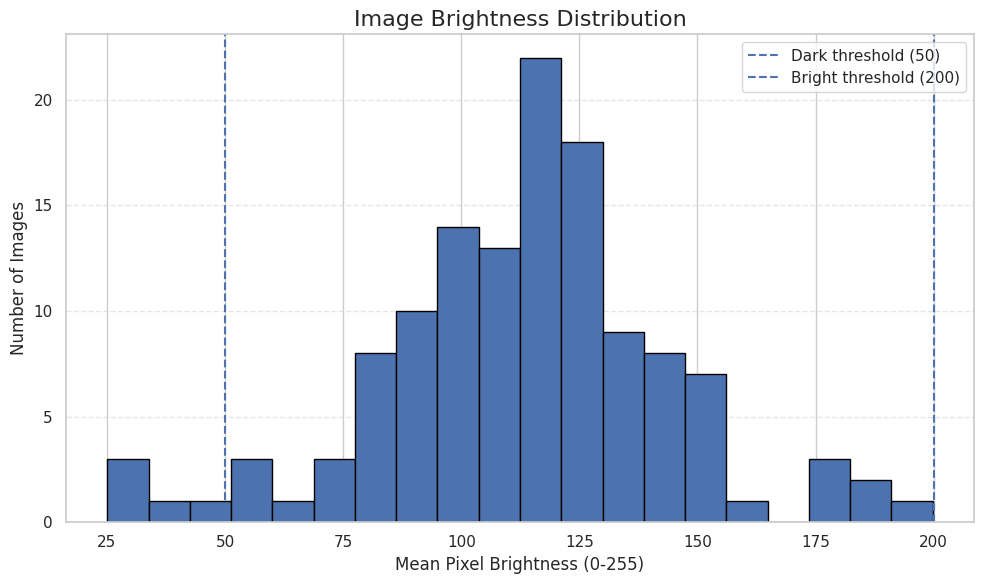

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(brightness_values, bins=20, edgecolor="black")

plt.axvline(50, linestyle="--", label="Dark threshold (50)")
plt.axvline(200, linestyle="--", label="Bright threshold (200)")

plt.title("Image Brightness Distribution", fontsize=16)
plt.xlabel("Mean Pixel Brightness (0-255)")
plt.ylabel("Number of Images")

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 7.4 Blur Detection using Laplacian Variance

In this step, we detect potentially blurry images using
the Laplacian Variance method.

The Laplacian operator detects edges and rapid changes
in image intensity.

The variance of the Laplacian is used as a blur score:
- Low variance indicates a potentially blurry image.
- High variance indicates a sharper image.

We use a threshold of 100 as a heuristic for identifying
potentially blurry images.

This method helps assess image sharpness and quality.

In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

blur_scores = []
blurry_images = []
sharp_images = []

BLUR_THRESHOLD = 100

for image_path in image_files:

    image = cv2.imread(str(image_path))

    if image is None:
        continue

    # Convert image to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Calculate Laplacian variance
    laplacian = cv2.Laplacian(gray, cv2.CV_64F)
    blur_score = laplacian.var()

    blur_scores.append(blur_score)

    # Categorize images
    if blur_score < BLUR_THRESHOLD:
        blurry_images.append(image_path.name)
    else:
        sharp_images.append(image_path.name)

# Display results
print("=" * 40)
print("BLUR DETECTION ANALYSIS")
print("=" * 40)

print("Images analyzed:", len(blur_scores))
print("Potentially blurry images:", len(blurry_images))
print("Sharp images:", len(sharp_images))

print("\nAverage blur score:", round(np.mean(blur_scores), 2))
print("Minimum blur score:", round(np.min(blur_scores), 2))
print("Maximum blur score:", round(np.max(blur_scores), 2))

print("\nThreshold used:", BLUR_THRESHOLD)

print("=" * 40)

BLUR DETECTION ANALYSIS
Images analyzed: 128
Potentially blurry images: 1
Sharp images: 127

Average blur score: 2713.71
Minimum blur score: 16.65
Maximum blur score: 29508.85

Threshold used: 100


### 7.5 Blur Score Distribution Visualization

In this step, we visualize the Laplacian variance scores
of all images using a histogram.

The X-axis represents the blur score, and the Y-axis
represents the number of images.

A vertical threshold line is used to separate potentially
blurry images from sharper images.

This visualization helps understand the overall image
sharpness distribution of the dataset.

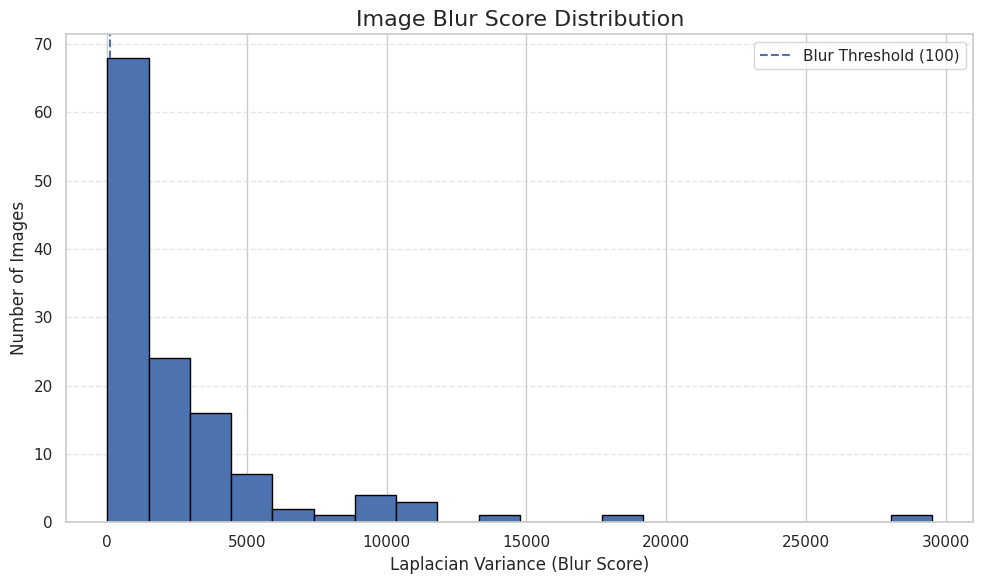

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(blur_scores, bins=20, edgecolor="black")

plt.axvline(
    BLUR_THRESHOLD,
    linestyle="--",
    label=f"Blur Threshold ({BLUR_THRESHOLD})"
)

plt.title("Image Blur Score Distribution", fontsize=16)
plt.xlabel("Laplacian Variance (Blur Score)")
plt.ylabel("Number of Images")

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 7.6 Visual Inspection of Potentially Blurry Vehicle Images

In this step, we select images containing vehicle-related
annotations and inspect only those images that have been
identified as potentially blurry.

We focus on bicycle, car, motorcycle, bus, train and truck.

This allows us to evaluate image quality specifically
for traffic-related objects instead of unrelated
categories such as household objects.

In [28]:
import matplotlib.pyplot as plt
import cv2
import math

# COCO vehicle class IDs
vehicle_class_ids = {1, 2, 3, 5, 6, 7}

# Find images containing vehicle annotations
vehicle_image_names = set()

for label_file in label_files:

    with open(label_file, "r") as f:
        lines = f.readlines()

    for line in lines:
        values = line.strip().split()

        if len(values) >= 5:
            class_id = int(float(values[0]))

            if class_id in vehicle_class_ids:
                vehicle_image_names.add(
                    label_file.stem + ".jpg"
                )

# Select blurry images containing vehicles
blurry_vehicle_images = [
    image_name
    for image_name in blurry_images
    if image_name in vehicle_image_names
]

print("Vehicle images found:", len(vehicle_image_names))
print("Potentially blurry vehicle images:",
      len(blurry_vehicle_images))

# Display images
sample_images = blurry_vehicle_images[:10]

if len(sample_images) == 0:

    print("No blurry vehicle images detected.")

else:

    cols = 2
    rows = math.ceil(len(sample_images) / cols)

    plt.figure(figsize=(14, 5 * rows))

    for i, image_name in enumerate(sample_images):

        image_path = IMAGE_DIR / image_name

        image = cv2.imread(str(image_path))

        if image is None:
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Calculate blur score directly
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
        score = cv2.Laplacian(
            gray, cv2.CV_64F
        ).var()

        plt.subplot(rows, cols, i + 1)
        plt.imshow(image)

        plt.title(
            f"{image_name}\nBlur Score: {score:.2f}"
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()

Vehicle images found: 26
Potentially blurry vehicle images: 0
No blurry vehicle images detected.


## 8. Annotation Validation

Annotation validation is the process of checking whether
the labels associated with images are correct and usable.

In this step, we check for missing annotation files
and empty annotation files.

Every image should have a corresponding annotation file
in the YOLO format.

Missing or empty annotations may affect model training
and dataset quality.

In [29]:
# Create image and label filename sets
image_stems = {image_path.stem for image_path in image_files}
label_stems = {label_path.stem for label_path in label_files}

# Find missing annotation files
missing_labels = image_stems - label_stems

# Find annotation files without corresponding images
orphan_labels = label_stems - image_stems

# Find empty annotation files
empty_labels = []

for label_file in label_files:

    if label_file.stat().st_size == 0:
        empty_labels.append(label_file.name)

# Display results
print("=" * 45)
print("ANNOTATION FILE VALIDATION")
print("=" * 45)

print("Total images:", len(image_stems))
print("Total annotation files:", len(label_stems))

print("\nMissing annotation files:", len(missing_labels))
print("Annotation files without images:", len(orphan_labels))
print("Empty annotation files:", len(empty_labels))

print("\nMissing label examples:", list(missing_labels)[:10])
print("Empty label examples:", empty_labels[:10])

print("=" * 45)

ANNOTATION FILE VALIDATION
Total images: 128
Total annotation files: 128

Missing annotation files: 2
Annotation files without images: 2
Empty annotation files: 0

Missing label examples: ['000000000250', '000000000508']
Empty label examples: []


### 8.2 Annotation Format and Bounding Box Validation

In this step, we validate the contents of YOLO annotation files.

Each annotation must contain exactly five values:
class ID, X-center, Y-center, width and height.

We check:
- Correct annotation format.
- Valid class IDs between 0 and 79.
- Normalized coordinates between 0 and 1.
- Positive bounding box width and height.
- Bounding boxes within image boundaries.

This helps identify incorrect or invalid annotations
before model training.

In [30]:
# Annotation validation

total_annotations = 0
valid_annotations = 0

invalid_format = []
invalid_class_ids = []
invalid_coordinates = []
invalid_dimensions = []
out_of_bounds_boxes = []

for label_file in label_files:

    with open(label_file, "r") as f:
        lines = f.readlines()

    for line_number, line in enumerate(lines, start=1):

        line = line.strip()

        if not line:
            continue

        total_annotations += 1
        values = line.split()

        # Check number of values
        if len(values) != 5:
            invalid_format.append(
                (label_file.name, line_number, line)
            )
            continue

        try:
            class_id = int(values[0])
            x_center = float(values[1])
            y_center = float(values[2])
            width = float(values[3])
            height = float(values[4])

        except ValueError:
            invalid_format.append(
                (label_file.name, line_number, line)
            )
            continue

        # Check class ID
        if class_id < 0 or class_id >= len(class_names):
            invalid_class_ids.append(
                (label_file.name, line_number, class_id)
            )
            continue

        # Check normalized coordinates
        if not (
            0 <= x_center <= 1 and
            0 <= y_center <= 1 and
            0 <= width <= 1 and
            0 <= height <= 1
        ):
            invalid_coordinates.append(
                (label_file.name, line_number, values)
            )
            continue

        # Check positive dimensions
        if width <= 0 or height <= 0:
            invalid_dimensions.append(
                (label_file.name, line_number, values)
            )
            continue

        # Check bounding box boundaries
        x_min = x_center - width / 2
        x_max = x_center + width / 2
        y_min = y_center - height / 2
        y_max = y_center + height / 2

        if (
            x_min < 0 or x_max > 1 or
            y_min < 0 or y_max > 1
        ):
            out_of_bounds_boxes.append(
                (label_file.name, line_number, values)
            )
            continue

        valid_annotations += 1


# Display validation results
print("=" * 50)
print("ANNOTATION CONTENT VALIDATION")
print("=" * 50)

print("Total annotations:", total_annotations)
print("Valid annotations:", valid_annotations)

print("\nInvalid format:", len(invalid_format))
print("Invalid class IDs:", len(invalid_class_ids))
print("Invalid coordinates:", len(invalid_coordinates))
print("Invalid dimensions:", len(invalid_dimensions))
print("Out-of-bound boxes:", len(out_of_bounds_boxes))

print("=" * 50)

ANNOTATION CONTENT VALIDATION
Total annotations: 941
Valid annotations: 899

Invalid format: 0
Invalid class IDs: 0
Invalid coordinates: 0
Invalid dimensions: 0
Out-of-bound boxes: 42


### 8.3 Visual Inspection of Out-of-Bound Bounding Boxes

In this step, we visually inspect bounding boxes that
were identified as out-of-bound during annotation validation.

We display the corresponding images and bounding boxes.

The flagged bounding box is highlighted in red, while
other annotations are shown in green.

Visual inspection helps determine whether the bounding
boxes are incorrectly annotated or only slightly
extend beyond the image boundaries.

This step helps verify annotation quality before
deciding whether corrections are necessary.

In [31]:
import cv2
import matplotlib.pyplot as plt
import math

# Select unique images with out-of-bound annotations
flagged_image_names = list(dict.fromkeys(
    item[0] for item in out_of_bounds_boxes
))

sample_names = flagged_image_names[:6]

print("Images containing out-of-bound boxes:",
      len(flagged_image_names))

print("Displaying sample images:",
      len(sample_names))

if len(sample_names) == 0:

    print("No out-of-bound images to display.")

else:

    cols = 2
    rows = math.ceil(len(sample_names) / cols)

    plt.figure(figsize=(14, 6 * rows))

    for i, image_name in enumerate(sample_names):

        image_path = IMAGE_DIR / image_name

        image = cv2.imread(str(image_path))

        if image is None:
            continue

        h, w = image.shape[:2]

        label_path = LABEL_DIR / (
            image_name.replace(".jpg", ".txt")
        )

        with open(label_path, "r") as f:
            lines = f.readlines()

        # Draw bounding boxes
        for line_number, line in enumerate(lines, start=1):

            values = line.strip().split()

            if len(values) != 5:
                continue

            class_id = int(float(values[0]))
            xc, yc, bw, bh = map(float, values[1:])

            # Convert normalized coordinates to pixels
            x1 = int((xc - bw / 2) * w)
            y1 = int((yc - bh / 2) * h)
            x2 = int((xc + bw / 2) * w)
            y2 = int((yc + bh / 2) * h)

            # Flag the out-of-bound annotation
            is_flagged = any(
                item[0] == image_name and
                item[1] == line_number
                for item in out_of_bounds_boxes
            )

            color = (0, 0, 255) if is_flagged else (0, 255, 0)

            # Clip coordinates for display
            x1_display = max(0, min(x1, w - 1))
            y1_display = max(0, min(y1, h - 1))
            x2_display = max(0, min(x2, w - 1))
            y2_display = max(0, min(y2, h - 1))

            cv2.rectangle(
                image,
                (x1_display, y1_display),
                (x2_display, y2_display),
                color,
                2
            )

            class_name = class_names[class_id]

            cv2.putText(
                image,
                class_name,
                (x1_display, max(y1_display - 5, 15)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                color,
                1
            )

        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        plt.subplot(rows, cols, i + 1)
        plt.imshow(image_rgb)
        plt.title(image_name)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

Images containing out-of-bound boxes: 33
Displaying sample images: 6


<Figure size 1400x1800 with 0 Axes>

## 9. Bounding Box Visualization

In this step, we visualize the annotations on dataset images.

Bounding boxes are drawn around detected objects using
the annotation coordinates.

Each bounding box is displayed with its corresponding
class name.

This visualization helps verify whether the annotations
accurately identify the objects and their locations.

It also helps detect incorrect bounding box positions,
missing objects and labeling errors.

Images containing traffic objects: 24


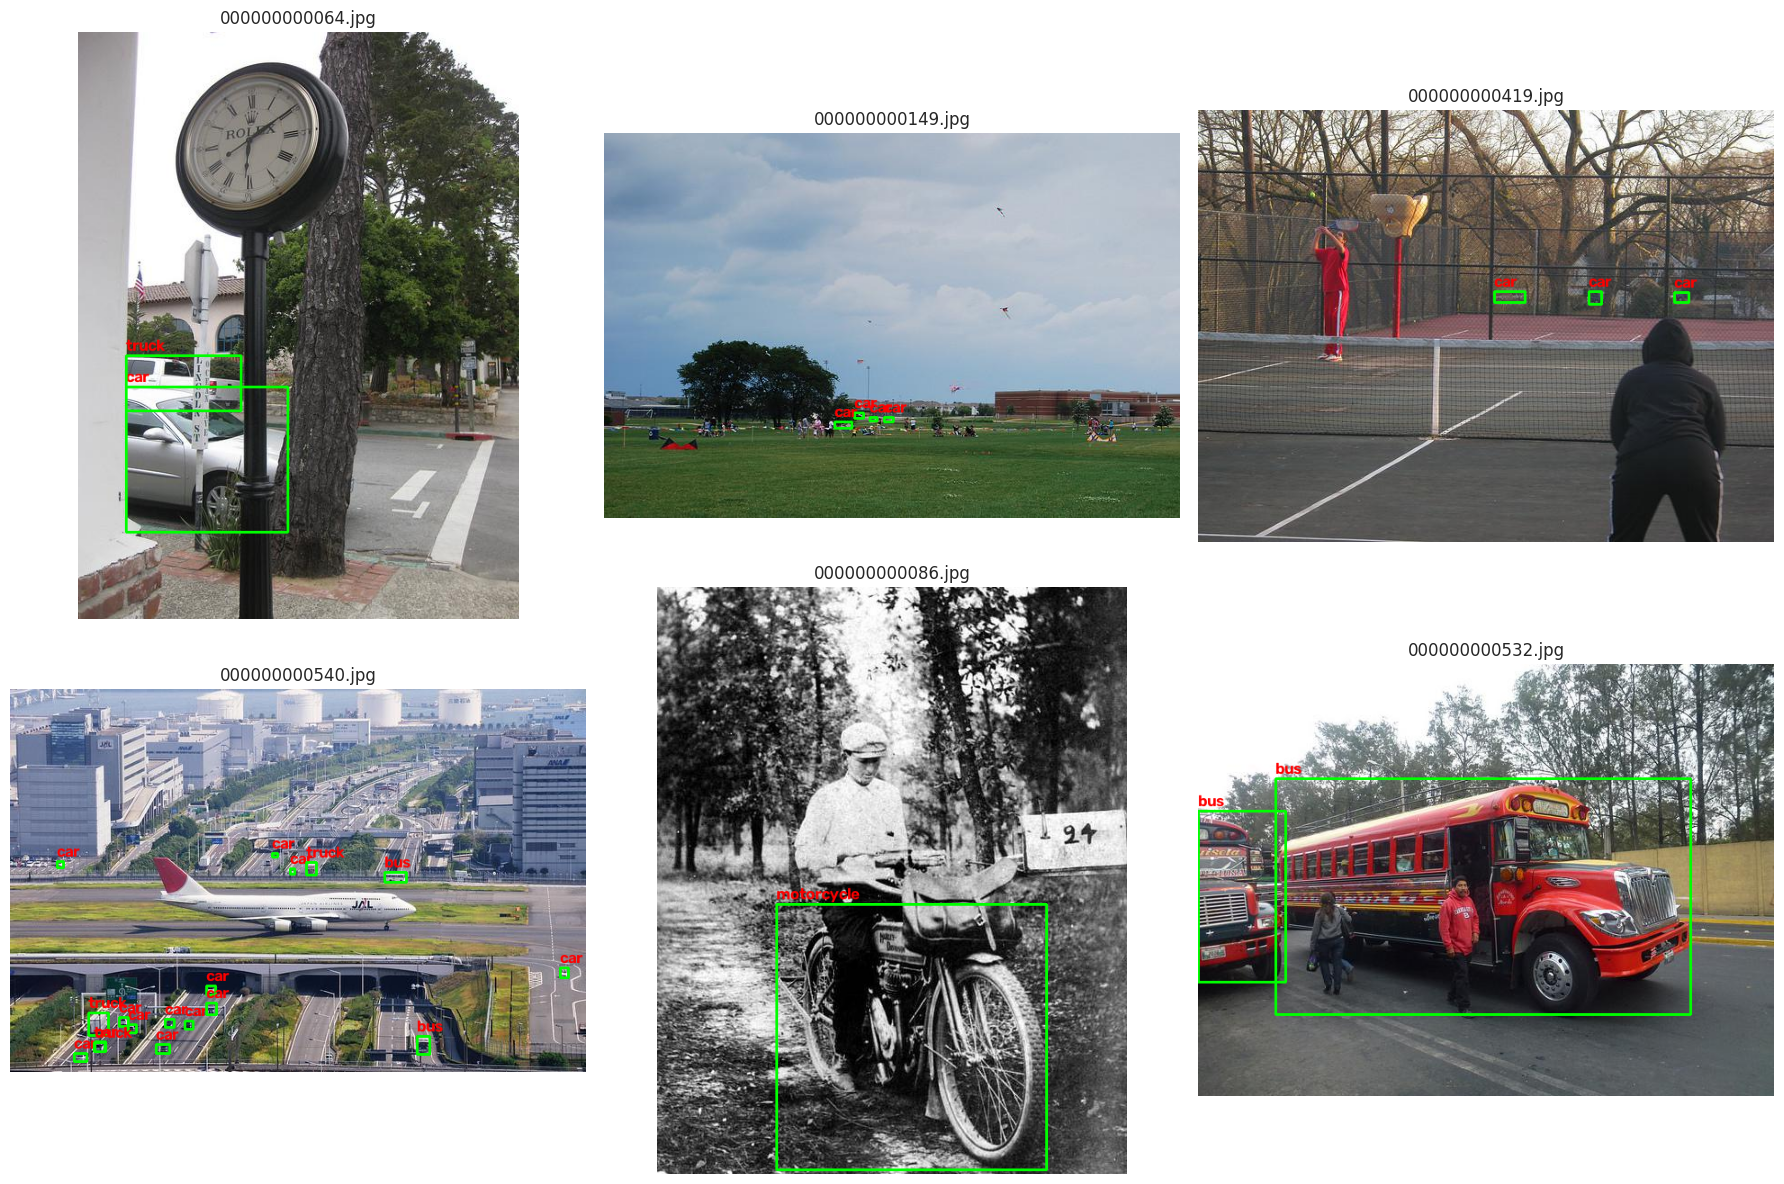

In [34]:
import cv2
import matplotlib.pyplot as plt
import random

# Traffic-related COCO classes
vehicle_ids = {
    1: "bicycle",
    2: "car",
    3: "motorcycle",
    5: "bus",
    6: "train",
    7: "truck"
}

# Find images containing at least one traffic object
traffic_images = []

for image_path in image_files:
    label_path = LABEL_DIR / (image_path.stem + ".txt")

    if not label_path.exists():
        continue

    with open(label_path, "r") as f:
        annotations = f.readlines()

    has_vehicle = False

    for annotation in annotations:
        values = annotation.strip().split()

        if len(values) == 5:
            class_id = int(float(values[0]))

            if class_id in vehicle_ids:
                has_vehicle = True
                break

    if has_vehicle:
        traffic_images.append(image_path)

print("Images containing traffic objects:", len(traffic_images))

# Select up to 6 traffic images
sample_images = random.sample(
    traffic_images,
    min(6, len(traffic_images))
)

# Display traffic images with bounding boxes
plt.figure(figsize=(18, 12))

for i, image_path in enumerate(sample_images):

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    height, width = image.shape[:2]

    label_path = LABEL_DIR / (image_path.stem + ".txt")

    with open(label_path, "r") as f:
        annotations = f.readlines()

    for annotation in annotations:

        values = annotation.strip().split()

        if len(values) != 5:
            continue

        class_id = int(float(values[0]))

        # Draw only traffic-related objects
        if class_id not in vehicle_ids:
            continue

        x_center, y_center, box_width, box_height = map(
            float, values[1:]
        )

        # Convert normalized coordinates to pixel coordinates
        x1 = int((x_center - box_width / 2) * width)
        y1 = int((y_center - box_height / 2) * height)
        x2 = int((x_center + box_width / 2) * width)
        y2 = int((y_center + box_height / 2) * height)

        # Keep bounding boxes within image boundaries
        x1 = max(0, min(x1, width - 1))
        y1 = max(0, min(y1, height - 1))
        x2 = max(0, min(x2, width - 1))
        y2 = max(0, min(y2, height - 1))

        # Draw bounding box
        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        # Draw class label
        label = vehicle_ids[class_id]

        cv2.putText(
            image,
            label,
            (x1, max(y1 - 5, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 0, 0),
            2
        )

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(image_path.name)
    plt.axis("off")

plt.tight_layout()
plt.show()

## 10. Dataset Audit Summary and Final Report

In this final step, we summarize the results obtained
during dataset auditing and visualization.

The report includes:
- Dataset statistics.
- Class distribution.
- Vehicle class distribution.
- Image dimensions and quality.
- Brightness analysis.
- Blur detection.
- Annotation validation.

The final report provides an overall understanding of
dataset quality and identifies possible issues that
should be considered before model training.

In [33]:
# FINAL DATASET AUDIT REPORT

total_images = len(image_files)
total_labels = len(label_files)
total_objects = sum(class_counts.values())

valid_percentage = (
    (valid_annotations / total_annotations) * 100
    if total_annotations > 0 else 0
)

print("=" * 65)
print("          DATASET AUDIT AND VISUALIZATION REPORT")
print("=" * 65)

print("\n1. DATASET OVERVIEW")
print("-" * 40)
print("Total images:", total_images)
print("Total annotation files:", total_labels)
print("Total object annotations:", total_objects)
print("Total classes:", len(class_names))
print("Classes present:", len(class_counts))
print("Classes absent:", len(class_names) - len(class_counts))

print("\n2. CLASS DISTRIBUTION")
print("-" * 40)

most_common_class = class_counts.most_common(1)[0]
print("Most frequent class:",
      class_names[most_common_class[0]])
print("Number of objects:",
      most_common_class[1])

print("Vehicle objects:", sum(vehicle_distribution.values()))

print("\n3. IMAGE QUALITY")
print("-" * 40)
print("Valid images:", valid_images)
print("Corrupted images:", len(corrupted_images))
print("Average width:", round(np.mean(widths), 2))
print("Average height:", round(np.mean(heights), 2))

print("\n4. BRIGHTNESS ANALYSIS")
print("-" * 40)
print("Dark images:", len(dark_images))
print("Normal images:", len(normal_images))
print("Bright images:", len(bright_images))
print("Average brightness:",
      round(np.mean(brightness_values), 2))

print("\n5. BLUR DETECTION")
print("-" * 40)
print("Potentially blurry images:", len(blurry_images))
print("Sharp images:", len(sharp_images))
print("Blur threshold:", BLUR_THRESHOLD)

print("\n6. ANNOTATION VALIDATION")
print("-" * 40)
print("Total annotations:", total_annotations)
print("Valid annotations:", valid_annotations)
print("Valid annotation percentage:",
      round(valid_percentage, 2), "%")
print("Missing labels:", len(missing_labels))
print("Empty labels:", len(empty_labels))
print("Invalid format:", len(invalid_format))
print("Invalid class IDs:", len(invalid_class_ids))
print("Invalid coordinates:", len(invalid_coordinates))
print("Invalid dimensions:", len(invalid_dimensions))
print("Out-of-bound boxes:", len(out_of_bounds_boxes))

print("\n7. VEHICLE ANALYSIS")
print("-" * 40)

for vehicle, count in vehicle_distribution.items():
    print(f"{vehicle}: {count}")

print("\n8. FINAL CONCLUSION")
print("-" * 40)

print("""
The dataset audit was successfully completed.

The dataset contains images from multiple object classes
with an imbalanced class distribution.

Image quality was evaluated using dimensions,
brightness and Laplacian variance.

Annotation files were checked for missing labels,
invalid formats, class IDs, coordinates and bounding boxes.

The audit results provide useful information about
dataset quality and preprocessing requirements before
model training.
""")

print("=" * 65)
print("              DATASET AUDIT COMPLETED")
print("=" * 65)

          DATASET AUDIT AND VISUALIZATION REPORT

1. DATASET OVERVIEW
----------------------------------------
Total images: 128
Total annotation files: 128
Total object annotations: 941
Total classes: 80
Classes present: 71
Classes absent: 9

2. CLASS DISTRIBUTION
----------------------------------------
Most frequent class: person
Number of objects: 261
Vehicle objects: 83

3. IMAGE QUALITY
----------------------------------------
Valid images: 128
Corrupted images: 0
Average width: 578.86
Average height: 492.31

4. BRIGHTNESS ANALYSIS
----------------------------------------
Dark images: 4
Normal images: 124
Bright images: 0
Average brightness: 113.18

5. BLUR DETECTION
----------------------------------------
Potentially blurry images: 1
Sharp images: 127
Blur threshold: 100

6. ANNOTATION VALIDATION
----------------------------------------
Total annotations: 941
Valid annotations: 899
Valid annotation percentage: 95.54 %
Missing labels: 2
Empty labels: 0
Invalid format: 0
Invalid 

## Conclusion

Dataset auditing and visualization were successfully
performed on the COCO128 dataset.

The dataset contains 128 images and 941 object annotations
belonging to 80 classes. Class distribution analysis
revealed an imbalance, with the person class being
the most frequent.

Image quality was assessed through dimension analysis,
brightness analysis and blur detection. All 128 images
were readable, and four images were identified as dark.

Annotation validation identified 42 out-of-bound bounding
boxes, which were further examined through visualization.

Overall, dataset auditing helps identify data quality
issues, understand class imbalance and verify annotations
before training an object detection model.